In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from pyproj import Proj

from em31_processing import read_em31

/opt/homebrew/Caskroom/miniconda/base/envs/gpgn-318/lib/python3.12/site-packages/pyproj/network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)


In [3]:
files = [
    "../../Data/EM_31_Data/molly2onyx.R31",
    "../../Data/EM_31_Data/mollyonyx.R31",
    "../../Data/EM_31_Data/onyxsmt.R31",
    "../../Data/EM_31_Data/onyxtms.R31"
]

datasets = {}

for file in files:

    data, gps = read_em31(file)

    if data.empty:
        print(f"{Path(file).name}: No measurements found")
        continue

    datasets[Path(file).stem] = {
        "data": data,
        "gps": gps
    }

    print(f"\n{Path(file).name}")
    print(f"Measurements: {len(data)}")
    print(f"GPS fixes: {len(gps)}")
    print(f"Segments: {data['segment'].nunique()}")


molly2onyx.R31
Measurements: 1529
GPS fixes: 274
Segments: 5

mollyonyx.R31
Measurements: 1466
GPS fixes: 0
Segments: 5

onyxsmt.R31
Measurements: 119
GPS fixes: 21
Segments: 1
onyxtms.R31: No measurements found


In [5]:
survey = "mollyonyx"

data = datasets[survey]["data"].copy()
gps = datasets[survey]["gps"].copy()

display(data.head())

,segment,channel_1,channel_2,counter
0,0,-40,312,1942026
1,0,-41,308,1942205
2,0,-42,308,1942384
3,0,-42,312,1942563
4,0,-44,316,1942743


In [6]:
data["conductivity"] = -data["channel_1"] / 4
data["inphase"] = -data["channel_2"] / 400

display(data.head())

,segment,channel_1,channel_2,counter,conductivity,inphase
0,0,-40,312,1942026,10.00,-0.78
1,0,-41,308,1942205,10.25,-0.77
2,0,-42,308,1942384,10.50,-0.77
3,0,-42,312,1942563,10.50,-0.78
4,0,-44,316,1942743,11.00,-0.79


In [7]:
display(
    data[["conductivity", "inphase"]].describe()
)

,conductivity,inphase
count,1466.000000,1466.000000
mean,16.250853,-0.615694
std,5.563905,0.141472
min,9.000000,-0.970000
25%,11.000000,-0.690000
50%,14.000000,-0.628750
75%,22.000000,-0.520000
max,32.000000,0.765000


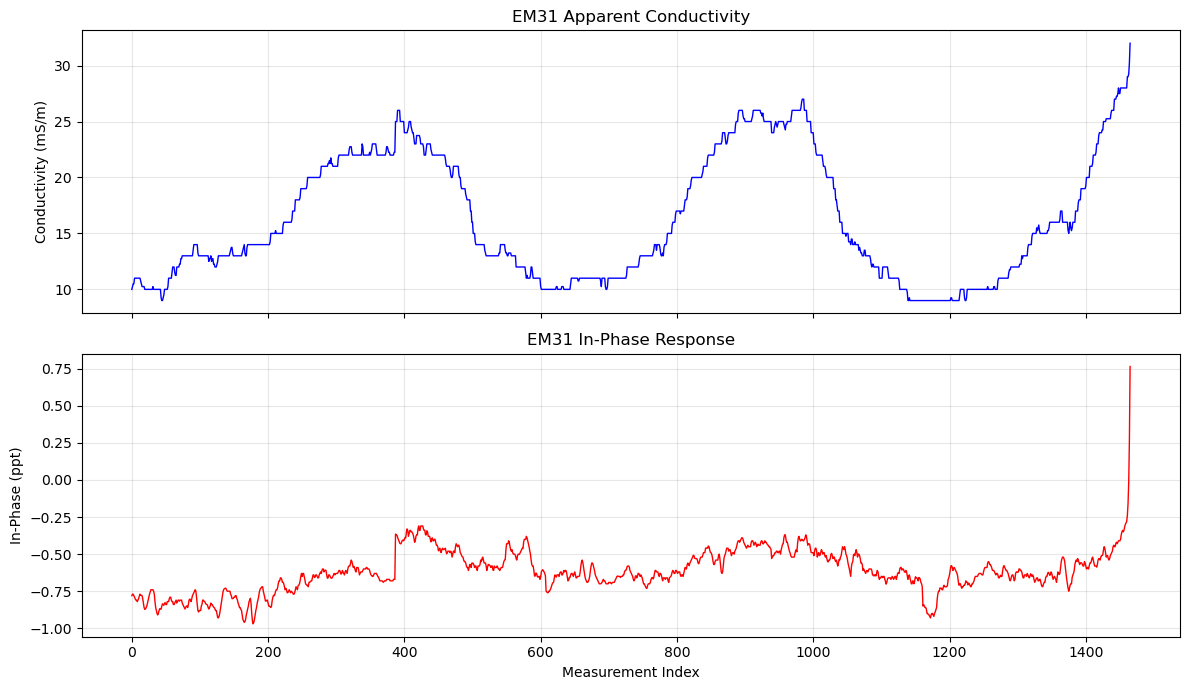

In [8]:
fig, axes = plt.subplots(
    2, 1,
    figsize=(12, 7),
    sharex=True
)

axes[0].plot(
    data["conductivity"],
    color="blue",
    linewidth=1
)

axes[0].set_title("EM31 Apparent Conductivity")
axes[0].set_ylabel("Conductivity (mS/m)")
axes[0].grid(alpha=0.3)

axes[1].plot(
    data["inphase"],
    color="red",
    linewidth=1
)

axes[1].set_title("EM31 In-Phase Response")
axes[1].set_xlabel("Measurement Index")
axes[1].set_ylabel("In-Phase (ppt)")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

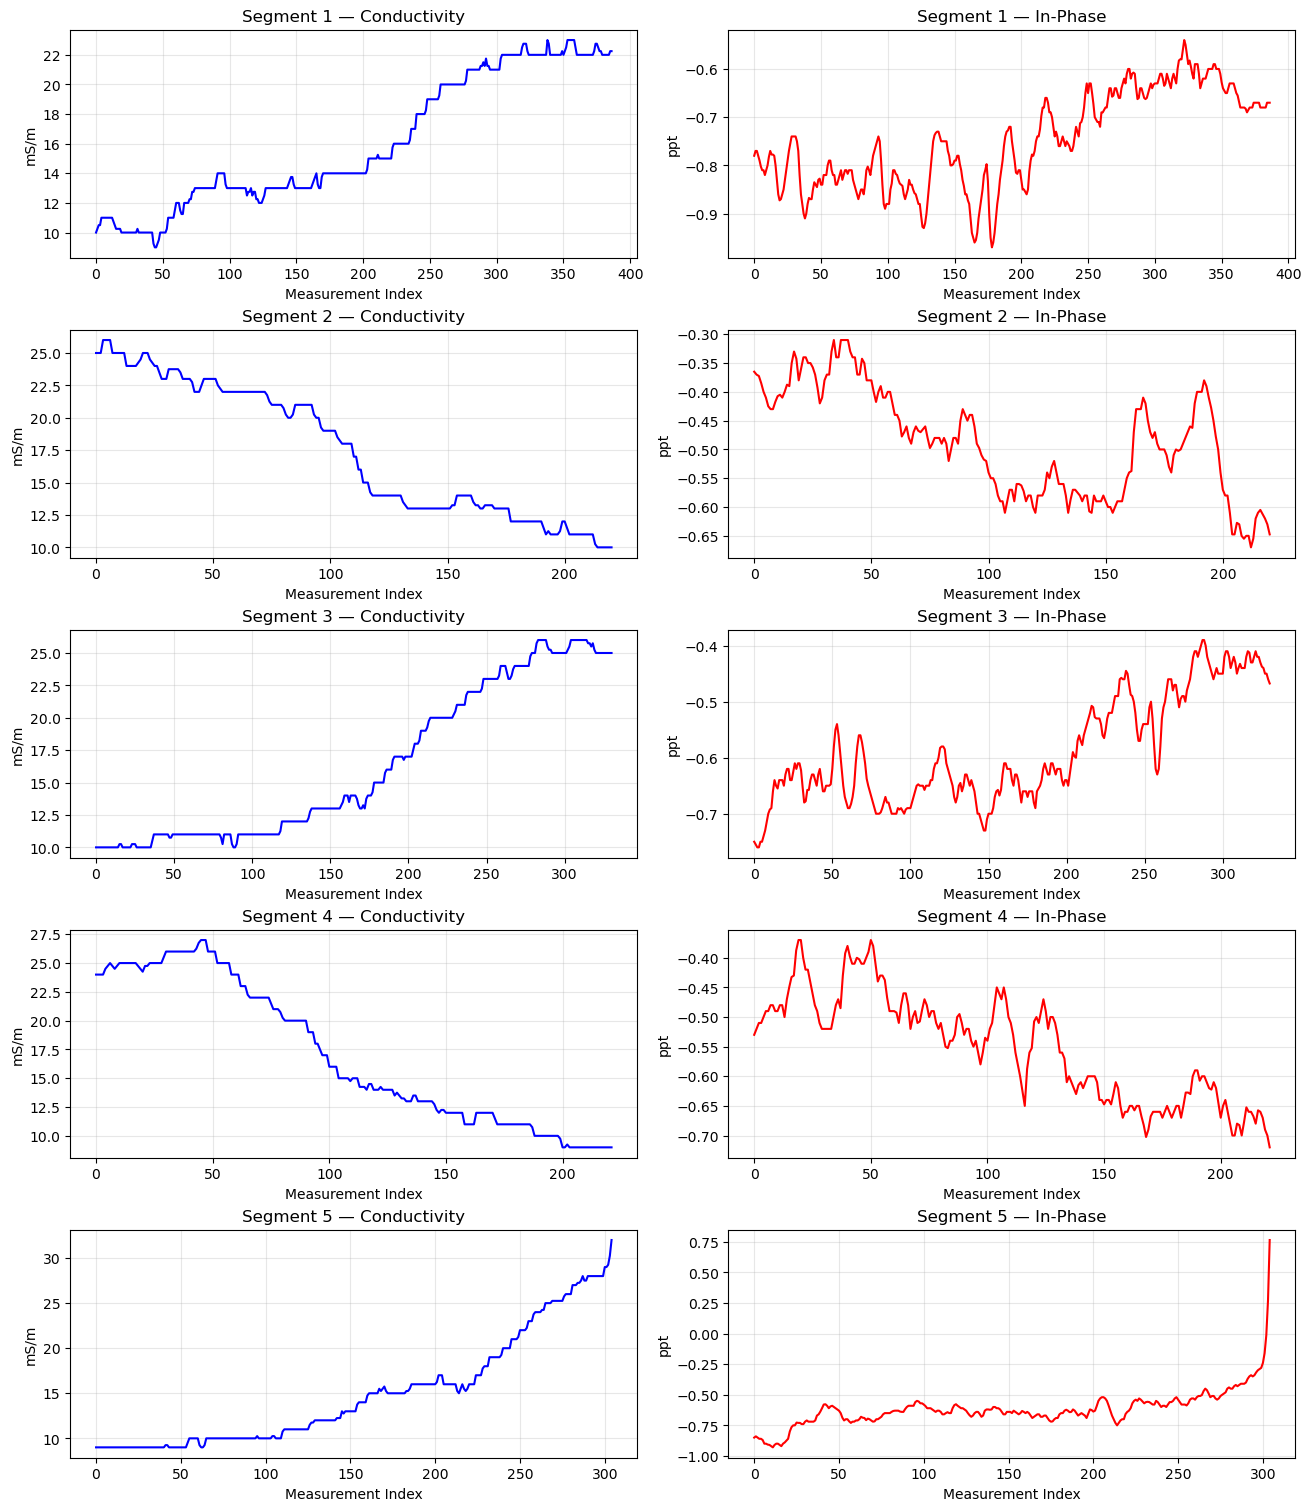

In [9]:
segments = sorted(data["segment"].unique())

fig, axes = plt.subplots(
    len(segments), 2,
    figsize=(13, 3 * len(segments)),
    constrained_layout=True
)

for i, seg in enumerate(segments):

    line = data[data["segment"] == seg]
    x = np.arange(len(line))

    axes[i, 0].plot(
        x, line["conductivity"],
        color="blue"
    )

    axes[i, 0].set_title(
        f"Segment {seg + 1} — Conductivity"
    )
    axes[i, 0].set_ylabel("mS/m")
    axes[i, 0].grid(alpha=0.3)

    axes[i, 1].plot(
        x, line["inphase"],
        color="red"
    )

    axes[i, 1].set_title(
        f"Segment {seg + 1} — In-Phase"
    )
    axes[i, 1].set_ylabel("ppt")
    axes[i, 1].grid(alpha=0.3)

    for ax in axes[i]:
        ax.set_xlabel("Measurement Index")

plt.show()

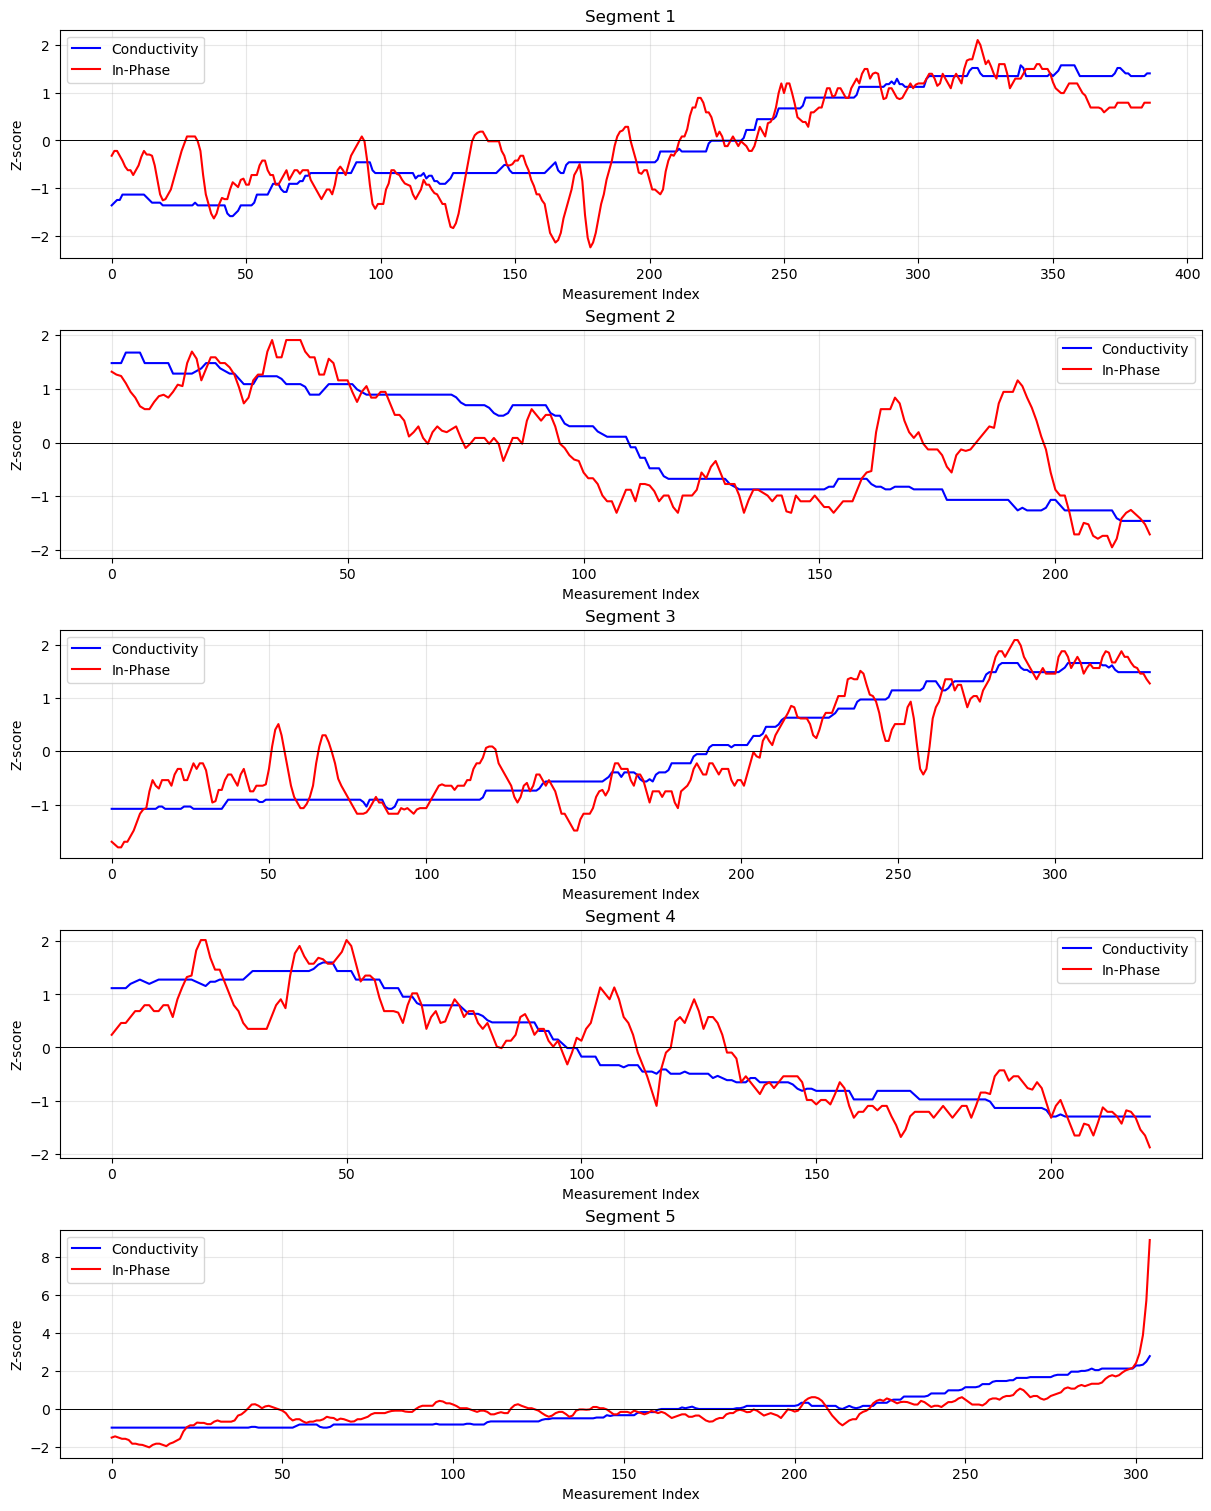

In [10]:
fig, axes = plt.subplots(
    len(segments), 1,
    figsize=(12, 3 * len(segments)),
    constrained_layout=True
)

for i, seg in enumerate(segments):

    line = data[data["segment"] == seg]

    cond = line["conductivity"]
    phase = line["inphase"]

    cond_std = cond.std()
    phase_std = phase.std()

    cond_norm = (
        (cond - cond.mean()) / cond_std
        if cond_std > 0 else cond * 0
    )

    phase_norm = (
        (phase - phase.mean()) / phase_std
        if phase_std > 0 else phase * 0
    )

    axes[i].plot(
        np.arange(len(line)),
        cond_norm,
        label="Conductivity",
        color="blue"
    )

    axes[i].plot(
        np.arange(len(line)),
        phase_norm,
        label="In-Phase",
        color="red"
    )

    axes[i].axhline(0, color="black", linewidth=0.7)
    axes[i].set_title(f"Segment {seg + 1}")
    axes[i].set_ylabel("Z-score")
    axes[i].set_xlabel("Measurement Index")
    axes[i].legend()
    axes[i].grid(alpha=0.3)

plt.show()

In [11]:
for name, survey_data in datasets.items():

    print(
        f"{name}: "
        f"{len(survey_data['gps'])} GPS fixes"
    )

molly2onyx: 274 GPS fixes
mollyonyx: 0 GPS fixes
onyxsmt: 21 GPS fixes


In [12]:
survey = "molly2onyx"

data = datasets[survey]["data"].copy()
gps = datasets[survey]["gps"].copy()

print("Measurements:", len(data))
print("GPS fixes:", len(gps))
print("Segments:", data["segment"].nunique())

Measurements: 1529
GPS fixes: 274
Segments: 5


In [13]:
utm = Proj(
    proj="utm",
    zone=13,
    datum="WGS84",
    units="m"
)

gps["easting"], gps["northing"] = utm(
    gps["longitude"].to_numpy(),
    gps["latitude"].to_numpy()
)

display(gps.head())

,segment,utc,latitude,longitude,gps_quality,satellites,altitude_m,counter,easting,northing
0,0,202628.40,40.478917,-106.835614,4,29,2122.661,2671473,344408.412210,4.482533e+06
1,0,202629.40,40.478914,-106.835615,4,29,2122.723,2672475,344408.364638,4.482532e+06
2,0,202630.40,40.478908,-106.835614,4,29,2122.783,2673479,344408.382920,4.482532e+06
3,0,202631.40,40.478903,-106.835611,4,29,2122.872,2674480,344408.639501,4.482531e+06
4,0,202632.40,40.478898,-106.835610,4,29,2122.870,2675477,344408.725475,4.482531e+06


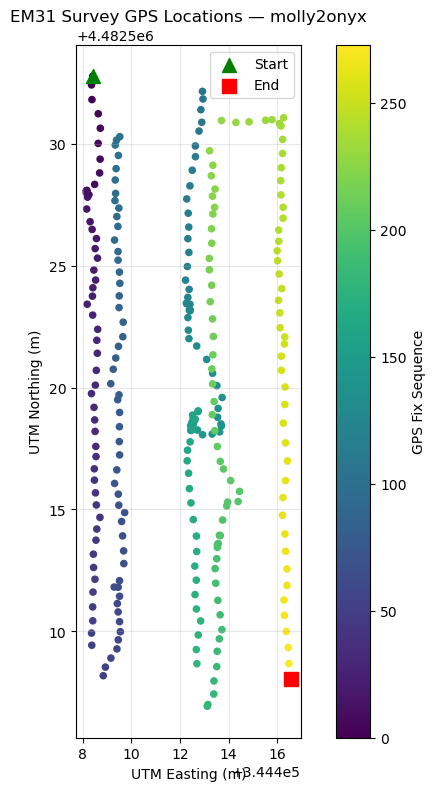

In [14]:
fig, ax = plt.subplots(figsize=(9, 9))

sc = ax.scatter(
    gps["easting"],
    gps["northing"],
    c=np.arange(len(gps)),
    cmap="viridis",
    s=20
)

plt.colorbar(sc, ax=ax, label="GPS Fix Sequence")

ax.scatter(
    gps["easting"].iloc[0],
    gps["northing"].iloc[0],
    color="green",
    s=100,
    marker="^",
    label="Start"
)

ax.scatter(
    gps["easting"].iloc[-1],
    gps["northing"].iloc[-1],
    color="red",
    s=100,
    marker="s",
    label="End"
)

ax.set_xlabel("UTM Easting (m)")
ax.set_ylabel("UTM Northing (m)")
ax.set_title("EM31 Survey GPS Locations — molly2onyx")
ax.set_aspect("equal")
ax.legend()
ax.grid(alpha=0.3)

plt.show()

In [15]:
mapped = []

for seg in sorted(data["segment"].unique()):

    em = data[data["segment"] == seg].copy()
    pos = gps[gps["segment"] == seg].copy()

    if len(pos) < 2:
        print(f"Skipping segment {seg}: insufficient GPS")
        continue

    pos = (
        pos.sort_values("counter")
        .drop_duplicates("counter")
    )

    em["easting"] = np.interp(
        em["counter"],
        pos["counter"],
        pos["easting"],
        left=np.nan,
        right=np.nan
    )

    em["northing"] = np.interp(
        em["counter"],
        pos["counter"],
        pos["northing"],
        left=np.nan,
        right=np.nan
    )

    mapped.append(em)

em_map = pd.concat(mapped, ignore_index=True)

em_map = em_map.dropna(
    subset=["easting", "northing"]
)

print("Mapped measurements:", len(em_map))
display(em_map.head())

Mapped measurements: 1505


,segment,channel_1,channel_2,counter,easting,northing
1,0,-88,213,2671491,344408.411355,4.482533e+06
2,0,-88,220,2671670,344408.402857,4.482533e+06
3,0,-91,224,2671849,344408.394359,4.482533e+06
4,0,-92,228,2672028,344408.385860,4.482533e+06
5,0,-92,228,2672207,344408.377362,4.482533e+06


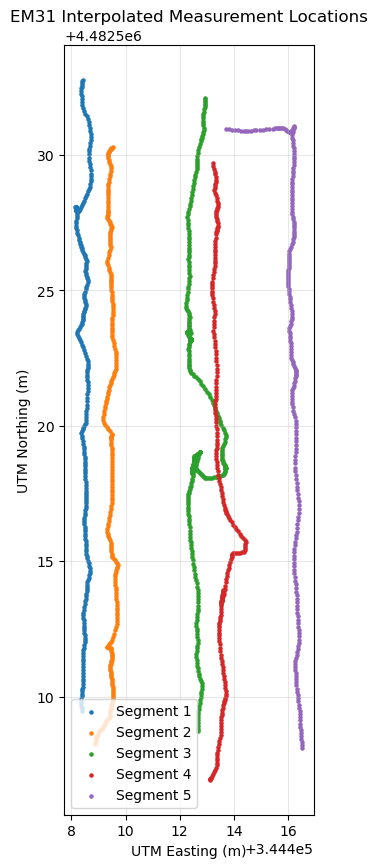

In [16]:
fig, ax = plt.subplots(figsize=(7, 10))

for seg, group in em_map.groupby("segment"):

    ax.scatter(
        group["easting"],
        group["northing"],
        s=5,
        label=f"Segment {seg + 1}"
    )

ax.set_xlabel("UTM Easting (m)")
ax.set_ylabel("UTM Northing (m)")
ax.set_title("EM31 Interpolated Measurement Locations")

ax.set_aspect("equal")
ax.legend()
ax.grid(alpha=0.3)

plt.show()

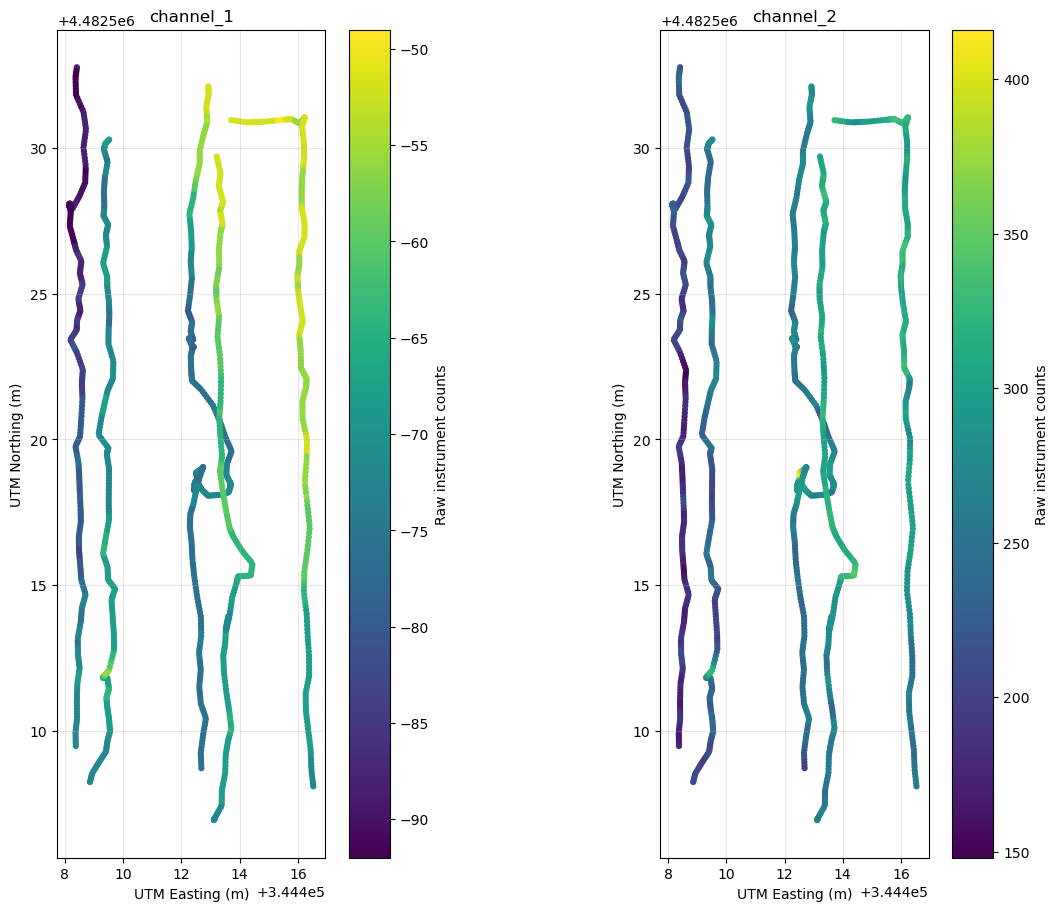

In [17]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 9),
    constrained_layout=True
)

for ax, channel in zip(
    axes,
    ["channel_1", "channel_2"]
):

    sc = ax.scatter(
        em_map["easting"],
        em_map["northing"],
        c=em_map[channel],
        cmap="viridis",
        s=12
    )

    ax.set_title(channel)
    ax.set_xlabel("UTM Easting (m)")
    ax.set_ylabel("UTM Northing (m)")
    ax.set_aspect("equal")
    ax.grid(alpha=0.3)

    plt.colorbar(
        sc,
        ax=ax,
        label="Raw instrument counts"
    )

plt.show()

In [18]:
em_map["conductivity"] = -em_map["channel_1"] / 4
em_map["inphase"] = -em_map["channel_2"] / 400

display(
    em_map[
        ["segment", "easting", "northing",
         "conductivity", "inphase"]
    ].head()
)

,segment,easting,northing,conductivity,inphase
1,0,344408.411355,4.482533e+06,22.00,-0.5325
2,0,344408.402857,4.482533e+06,22.00,-0.5500
3,0,344408.394359,4.482533e+06,22.75,-0.5600
4,0,344408.385860,4.482533e+06,23.00,-0.5700
5,0,344408.377362,4.482533e+06,23.00,-0.5700


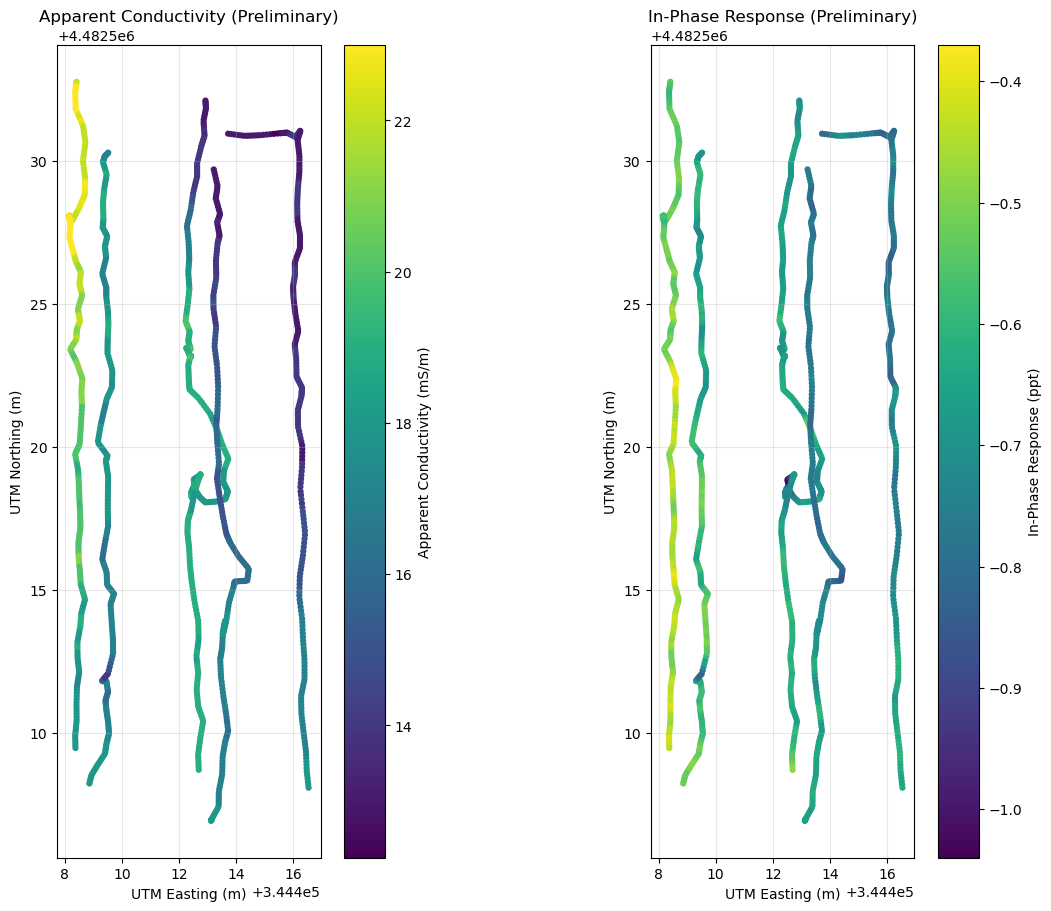

In [19]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 9),
    constrained_layout=True
)

channels = [
    ("conductivity", "Apparent Conductivity", "mS/m"),
    ("inphase", "In-Phase Response", "ppt")
]

for ax, (column, title, units) in zip(axes, channels):

    sc = ax.scatter(
        em_map["easting"],
        em_map["northing"],
        c=em_map[column],
        cmap="viridis",
        s=12
    )

    ax.set_title(title + " (Preliminary)")
    ax.set_xlabel("UTM Easting (m)")
    ax.set_ylabel("UTM Northing (m)")
    ax.set_aspect("equal")
    ax.grid(alpha=0.3)

    plt.colorbar(
        sc,
        ax=ax,
        label=f"{title} ({units})"
    )

plt.show()

In [20]:
em_map["conductivity_residual"] = (
    em_map["conductivity"]
    - em_map.groupby("segment")["conductivity"].transform("mean")
)

display(
    em_map.groupby("segment")[
        ["conductivity", "conductivity_residual"]
    ].agg(["mean", "std"]).round(3)
)

conductivity        conductivity_residual       
                mean    std                  mean    std
segment                                                 
0             20.755  1.714                  -0.0  1.714
1             17.474  0.867                   0.0  0.867
2             18.118  1.654                   0.0  1.654
3             15.824  1.497                   0.0  1.497
4             14.425  1.585                   0.0  1.585

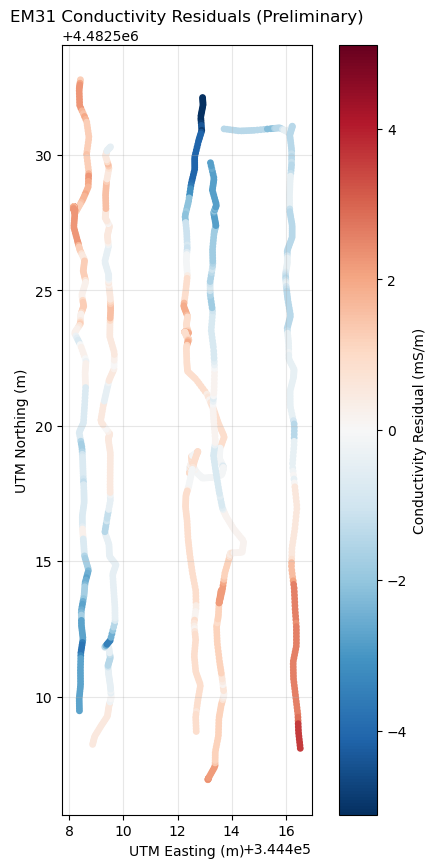

In [21]:
fig, ax = plt.subplots(figsize=(7, 10))

limit = np.nanmax(
    np.abs(em_map["conductivity_residual"])
)

sc = ax.scatter(
    em_map["easting"],
    em_map["northing"],
    c=em_map["conductivity_residual"],
    cmap="RdBu_r",
    vmin=-limit,
    vmax=limit,
    s=15
)

plt.colorbar(
    sc,
    ax=ax,
    label="Conductivity Residual (mS/m)"
)

ax.set_title("EM31 Conductivity Residuals (Preliminary)")
ax.set_xlabel("UTM Easting (m)")
ax.set_ylabel("UTM Northing (m)")
ax.set_aspect("equal")
ax.grid(alpha=0.3)

plt.show()